# 01 · Calibración: rendimientos, estadísticas y estados conjuntos

En este notebook se transforman los 65 cierres ajustados trimestrales de 2009 a 2025 en la información que necesita el modelo. Primero se calculan los 64 rendimientos trimestrales de cada activo, con sus estadísticas básicas y una gráfica de la evolución de los precios. Después, cada trimestre se clasifica según si cada activo subió o bajó, lo que da ocho combinaciones posibles, y para cada una se estima su probabilidad y el rendimiento promedio de cada activo. Esos valores se guardan en un archivo que ya no se modifica y del que leen todos los notebooks siguientes. 

In [1]:
import hashlib
import json
from datetime import datetime, timezone
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

## 1. Configuración y carga del bloque de calibración

Se verifica que el CSV no haya cambiado desde que lo guardó el notebook 00 y que ninguna fecha sea posterior al 31 de diciembre de 2025.

Los parámetros financieros $b = 100$, $M = 106$ y $\lambda = 4$ (en miles de USD, sección 3.1) se registran aquí para que todos los notebooks los lean del mismo archivo congelado.

In [2]:
TICKERS = ["SPY", "LQD", "GLD"]                              # orden fijo (sección 2.5)
STATE_ORDER = ["".join(s) for s in product("AB", repeat=3)]  # AAA, AAB, ..., BBB
ASSET_COLORS = {"SPY": "#1f77b4", "LQD": "#2ca02c", "GLD": "#d4a017"}

B_CAPITAL, M_GOAL, LAMBDA = 100.0, 106.0, 4.0   # miles de USD (sección 3.1)
N_RETURNS_EXPECTED = 64
CALIBRATION_END = pd.Timestamp("2025-12-31")

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CAL_DIR = ROOT / "data" / "calibration"
TABLES_DIR = ROOT / "results" / "tables"
FIGURES_DIR = ROOT / "results" / "figures"
PARAMS_DIR = ROOT / "results" / "parameters"
for d in [TABLES_DIR, FIGURES_DIR, PARAMS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

cal_meta = json.loads((CAL_DIR / "metadata.json").read_text(encoding="utf-8"))
cal_csv = ROOT / cal_meta["csv_file"]
assert sha256_of(cal_csv) == cal_meta["csv_sha256"], "El CSV de calibración cambió desde el notebook 00."

prices = pd.read_csv(cal_csv, dtype={"quarter": str, "date": str})
prices["date"] = pd.to_datetime(prices["date"])

assert len(prices) == N_RETURNS_EXPECTED + 1, "Se esperaban 65 precios por activo."
assert prices["j"].tolist() == list(range(N_RETURNS_EXPECTED + 1))
assert prices["date"].max() <= CALIBRATION_END, "Hay fechas posteriores a la calibración."
assert prices["quarter"].iloc[0] == "2009Q4" and prices["quarter"].iloc[-1] == "2025Q4"
assert (prices[TICKERS] > 0).all().all()

print(f"Calibración: {cal_csv.relative_to(ROOT)}")
print(f"Consulta original: {cal_meta['consulted_at_bogota']} · hash verificado")
print(f"Precios: {prices['date'].iloc[0].date()} (j=0) a {prices['date'].iloc[-1].date()} (j=64)")

Calibración: data/calibration/quarterly_adjclose_2009_2025.csv
Consulta original: 2026-10-04T16:26:02-05:00 · hash verificado
Precios: 2009-12-31 (j=0) a 2025-12-31 (j=64)


## 2. Rendimientos simples y factores brutos 

Para cada activo $i \in I = \{\text{SPY}, \text{LQD}, \text{GLD}\}$ y cada trimestre histórico $j = 1, \dots, 64$:

$$r_{i,j} = \frac{P_{i,j}}{P_{i,j-1}} - 1, \qquad R_{i,j} = 1 + r_{i,j}.$$

El trimestre $j = 1$ es enero–marzo de 2010 y usa como punto de partida el cierre de diciembre de 2009 ($j = 0$). No se calcula ningún rendimiento de 2009.

In [3]:
P = prices.set_index("j")[TICKERS].to_numpy(dtype=float)    # 65 x 3
R = P[1:] / P[:-1]                                          # 64 x 3, factores brutos
r = R - 1.0                                                 # 64 x 3, rendimientos simples

returns = prices.iloc[1:][["j", "quarter", "date"]].reset_index(drop=True)
for k, t in enumerate(TICKERS):
    returns[f"r_{t}"] = r[:, k]
for k, t in enumerate(TICKERS):
    returns[f"R_{t}"] = R[:, k]

assert len(returns) == N_RETURNS_EXPECTED and returns["j"].tolist() == list(range(1, 65))
assert np.all(R > 0), "Todos los factores deben ser positivos."
print(f"{len(returns)} rendimientos trimestrales por activo: "
      f"{returns['quarter'].iloc[0]} a {returns['quarter'].iloc[-1]}")
with pd.option_context("display.float_format", "{:.6f}".format):
    display(returns.head(4))

64 rendimientos trimestrales por activo: 2010Q1 a 2025Q4


,j,quarter,date,r_SPY,r_LQD,r_GLD,R_SPY,R_LQD,R_GLD
0,1,2010Q1,2010-03-31,0.054215,0.024246,0.015283,1.054215,1.024246,1.015283
1,2,2010Q2,2010-06-30,-0.113580,0.038719,0.116843,0.886420,1.038719,1.116843
2,3,2010Q3,2010-09-30,0.111616,0.055059,0.051200,1.111616,1.055059,1.051200
3,4,2010Q4,2010-12-31,0.107609,-0.026117,0.084513,1.107609,0.973883,1.084513


## 3. Estadísticas de los 64 rendimientos 

Se reportan media, desviación estándar, mínimo y máximo de $r_{i,j}$ por activo, en porcentaje trimestral. La desviación estándar es la **muestral** (divisor $n - 1 = 63$). También se indica en qué trimestre ocurrieron el mínimo y el máximo.

In [4]:
stats = pd.DataFrame(index=TICKERS)
stats["media (%)"] = 100 * r.mean(axis=0)
stats["desv. estándar (%)"] = 100 * r.std(axis=0, ddof=1)
stats["mínimo (%)"] = 100 * r.min(axis=0)
stats["trimestre del mínimo"] = [returns["quarter"].iloc[k] for k in r.argmin(axis=0)]
stats["máximo (%)"] = 100 * r.max(axis=0)
stats["trimestre del máximo"] = [returns["quarter"].iloc[k] for k in r.argmax(axis=0)]
stats["trimestres con r < 0"] = (r < 0).sum(axis=0)
stats.index.name = "activo"

with pd.option_context("display.float_format", "{:.3f}".format):
    display(stats)
stats.to_csv(TABLES_DIR / "01_return_statistics.csv", float_format="%.10f")

,media (%),desv. estándar (%),mínimo (%),trimestre del mínimo,máximo (%),trimestre del máximo,trimestres con r < 0
activo,,,,,,,
SPY,3.612,7.437,-19.448,2020Q1,20.162,2020Q2,13
LQD,1.069,3.701,-8.403,2022Q2,10.098,2023Q4,21
GLD,2.356,7.693,-22.881,2013Q2,19.002,2025Q1,23


## 4. Precios ajustados normalizados a 100 en diciembre de 2009 

Se normaliza cada serie con su propio cierre de diciembre de 2009: $100 \cdot P_{i,j} / P_{i,0}$. La gráfica usa los 65 cierres trimestrales que conserva la calibración, que son los mismos datos con que se estima el modelo.

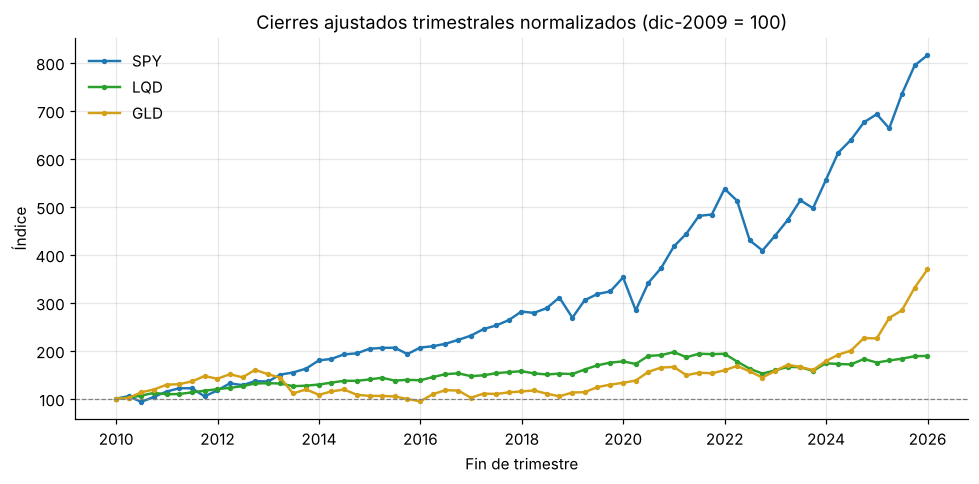

Valor final (dic-2025) del índice normalizado:
SPY    815.60
LQD    189.26
GLD    369.31


In [5]:
norm = 100 * prices[TICKERS] / prices[TICKERS].iloc[0]

fig, ax = plt.subplots(figsize=(9, 4.5))
for t in TICKERS:
    ax.plot(prices["date"], norm[t], marker="o", ms=2.5, lw=1.6, color=ASSET_COLORS[t], label=t)
ax.axhline(100, color="gray", lw=0.8, ls="--")
ax.set_title("Cierres ajustados trimestrales normalizados (dic-2009 = 100)")
ax.set_xlabel("Fin de trimestre")
ax.set_ylabel("Índice")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_normalized_prices.png")
plt.show()

print("Valor final (dic-2025) del índice normalizado:")
print(norm.iloc[-1].round(2).to_string())

## 5. Estados conjuntos, probabilidades y factores representativos 

Cada activo recibe la letra **B** si su rendimiento del trimestre es negativo ($r_{i,j} < 0$) y **A** en otro caso ($r_{i,j} \ge 0$). La terna se forma siempre en el orden SPY, LQD, GLD. Para cada $u \in U$:

$$J_u = \{j : \text{terna}(j) = u\}, \qquad n_u = |J_u|, \qquad \hat q_u = \frac{n_u}{64}, \qquad \hat R_i(u) = \frac{1}{n_u}\sum_{j \in J_u} R_{i,j}.$$

La probabilidad se estima contando coincidencias de los tres signos en el mismo trimestre. Si algún estado no aparece, no se promedia ni se le asigna probabilidad positiva: se elimina la rama y queda registrado.

In [6]:
signs = np.where(r < 0, "B", "A")                       # 64 x 3
returns["state"] = ["".join(row) for row in signs]

state_rows, removed_states = [], []
for u in STATE_ORDER:
    J_u = returns.index[returns["state"] == u]
    n_u = len(J_u)
    row = {"estado": u, "n_u": n_u, "q_hat": n_u / N_RETURNS_EXPECTED}
    if n_u == 0:
        removed_states.append(u)
        row.update({f"R_hat_{t}": np.nan for t in TICKERS})
    else:
        row.update({f"R_hat_{t}": R[J_u, k].mean() for k, t in enumerate(TICKERS)})
    row["trimestres"] = ", ".join(returns.loc[J_u, "quarter"])
    state_rows.append(row)
states = pd.DataFrame(state_rows).set_index("estado")

assert states["n_u"].sum() == N_RETURNS_EXPECTED, "Los conteos no suman 64."
assert np.isclose(states["q_hat"].sum(), 1.0), "Las probabilidades no suman 1."

if removed_states:
    print("ATENCIÓN: estados sin observaciones:", removed_states)
    print("Según la sección 2.5: revisen fechas y ajustes en el notebook 00. Si la ausencia persiste "
          "en una fuente comprobada, se elimina la rama y en validación se aplica la regla de "
          "respaldo de la sección 5.2.")
else:
    print("Las ocho combinaciones de signos aparecen al menos una vez.")

ACTIVE_STATES = [u for u in STATE_ORDER if u not in removed_states]
show = states.drop(columns="trimestres").copy()
show["q_hat"] = show["q_hat"].map("{:.6f}".format)
with pd.option_context("display.float_format", "{:.6f}".format):
    display(show)

Las ocho combinaciones de signos aparecen al menos una vez.


,n_u,q_hat,R_hat_SPY,R_hat_LQD,R_hat_GLD
estado,,,,,
AAA,31,0.484375,1.070526,1.034144,1.065740
AAB,6,0.093750,1.069237,1.020277,0.963796
ABA,3,0.046875,1.085100,0.986717,1.068594
ABB,11,0.171875,1.043089,0.977068,0.931211
BAA,3,0.046875,0.901860,1.031670,1.129822
BAB,3,0.046875,0.967833,1.014010,0.950266
BBA,4,0.062500,0.903526,0.962917,1.046330
BBB,3,0.046875,0.919115,0.935849,0.937469


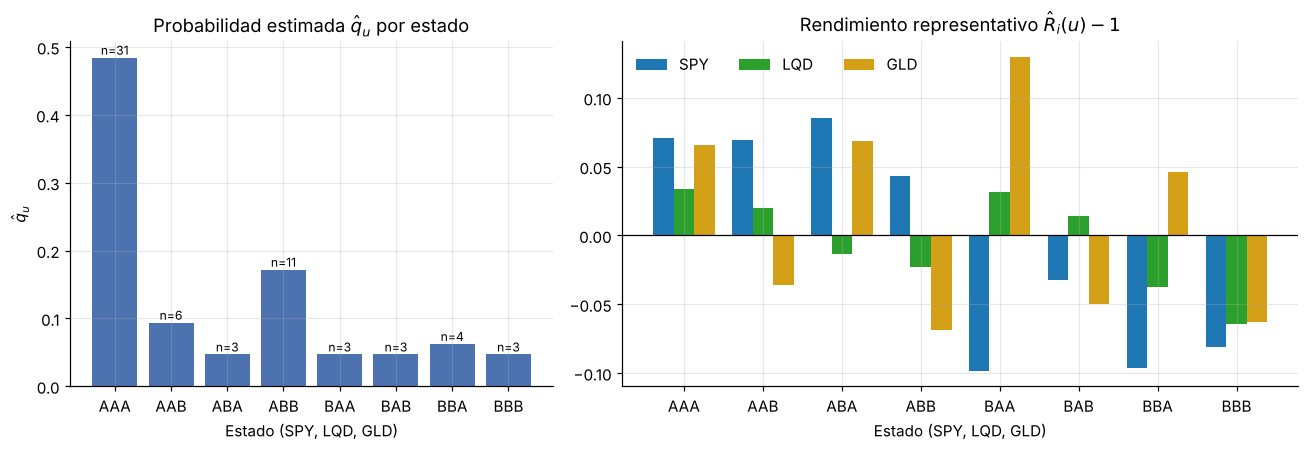

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})

ax = axes[0]
bars = ax.bar(STATE_ORDER, states["q_hat"], color="#4c72b0")
for b_, n in zip(bars, states["n_u"]):
    ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height(), f"n={n}",
            ha="center", va="bottom", fontsize=8)
ax.set_title(r"Probabilidad estimada $\hat q_u$ por estado")
ax.set_xlabel("Estado (SPY, LQD, GLD)")
ax.set_ylabel(r"$\hat q_u$")

ax = axes[1]
x = np.arange(len(STATE_ORDER)); w = 0.26
for k, t in enumerate(TICKERS):
    ax.bar(x + (k - 1) * w, states[f"R_hat_{t}"] - 1, w, color=ASSET_COLORS[t], label=t)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, STATE_ORDER)
ax.set_title(r"Rendimiento representativo $\hat R_i(u) - 1$")
ax.set_xlabel("Estado (SPY, LQD, GLD)")
ax.legend(frameon=False, ncol=3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_states_probabilities_factors.png")
plt.show()

### Diagnóstico: conteo conjunto frente al producto de marginales

Las probabilidades de los estados se estiman contando cuántas veces ocurrió cada combinación completa de subidas y bajadas. Una alternativa tentadora sería calcular por separado con qué frecuencia baja cada activo y multiplicar esas frecuencias, pero eso supondría que los tres activos se mueven sin ninguna relación entre sí, algo que los datos no respaldan. La tabla siguiente compara ambos cálculos solo para mostrar cuánto se distorsionaría la distribución con ese supuesto. Estos valores **no se usan en el modelo**.

In [8]:
p_down = (r < 0).mean(axis=0)                     
indep = []
for u in STATE_ORDER:
    pr = 1.0
    for k, letter in enumerate(u):
        pr *= p_down[k] if letter == "B" else 1 - p_down[k]
    indep.append(pr)
diag = pd.DataFrame({"q_hat (conjunto, se usa)": states["q_hat"],
                     "producto de marginales (NO se usa)": indep})
diag["diferencia"] = diag.iloc[:, 0] - diag.iloc[:, 1]
print("Frecuencia marginal de caída:", dict(zip(TICKERS, np.round(p_down, 4))))
print("Correlaciones muestrales de r:")
display(pd.DataFrame(np.corrcoef(r.T), index=TICKERS, columns=TICKERS).round(3))
with pd.option_context("display.float_format", "{:.4f}".format):
    display(diag)

Frecuencia marginal de caída: {'SPY': np.float64(0.2031), 'LQD': np.float64(0.3281), 'GLD': np.float64(0.3594)}
Correlaciones muestrales de r:


,SPY,LQD,GLD
SPY,1.000,0.438,0.072
LQD,0.438,1.000,0.549
GLD,0.072,0.549,1.000


,"q_hat (conjunto, se usa)",producto de marginales (NO se usa),diferencia
estado,,,
AAA,0.4844,0.3430,0.1414
AAB,0.0938,0.1924,-0.0987
ABA,0.0469,0.1675,-0.1206
ABB,0.1719,0.0940,0.0779
BAA,0.0469,0.0874,-0.0406
BAB,0.0469,0.0490,-0.0022
BBA,0.0625,0.0427,0.0198
BBB,0.0469,0.0240,0.0229


## 6. Variabilidad que se pierde al promediar cada grupo

El modelo representa cada estado con un solo número por activo, el promedio de sus rendimientos en los trimestres de ese grupo. Eso simplifica el problema, pero borra las diferencias entre trimestres del mismo grupo, y un activo puede parecer más estable en el árbol de lo que realmente fue. Para medir cuánto se pierde se hacen dos cosas.

Primero, para cada estado se muestra qué tan dispersos eran los rendimientos que se resumieron en $\hat R_i(u)$. Segundo, la variabilidad total de cada activo se separa en dos partes: la que hay **entre** los promedios de los grupos, que el árbol conserva, y la que hay dentro de cada grupo, que el árbol elimina:

$$\underbrace{\tfrac{1}{64}\sum_j (R_{i,j} - \bar R_i)^2}_{\text{total}} = \underbrace{\sum_u \hat q_u\,(\hat R_i(u) - \bar R_i)^2}_{\text{entre grupos}} + \underbrace{\tfrac{1}{64}\sum_u \sum_{j \in J_u} (R_{i,j} - \hat R_i(u))^2}_{\text{dentro de los grupos}}.$$

En esta descomposición se divide entre 64, y no entre 63 como en la desviación estándar de la sección 3, para que la igualdad se cumpla exactamente.

In [9]:
rows = []
for u in ACTIVE_STATES:
    J_u = returns.index[returns["state"] == u]
    for k, t in enumerate(TICKERS):
        v = R[J_u, k] - 1
        rows.append({"estado": u, "activo": t, "n_u": len(J_u),
                     "media r (%)": 100 * v.mean(),
                     "desv. dentro (%)": 100 * v.std(ddof=1) if len(v) > 1 else np.nan,
                     "mín r (%)": 100 * v.min(), "máx r (%)": 100 * v.max()})
within = pd.DataFrame(rows).set_index(["estado", "activo"])
with pd.option_context("display.float_format", "{:.3f}".format):
    wide = within.unstack("activo")[["media r (%)", "desv. dentro (%)"]]
    display(wide.reindex(columns=pd.MultiIndex.from_product(
        [["media r (%)", "desv. dentro (%)"], TICKERS])).reindex(ACTIVE_STATES))

R_bar_sample = R.mean(axis=0)
q = states.loc[ACTIVE_STATES, "q_hat"].to_numpy()
Rh = states.loc[ACTIVE_STATES, [f"R_hat_{t}" for t in TICKERS]].to_numpy()
var_total = ((R - R_bar_sample) ** 2).mean(axis=0)
var_between = (q[:, None] * (Rh - R_bar_sample) ** 2).sum(axis=0)
var_within = var_total - var_between

decomp = pd.DataFrame({
    "desv. total de r, ÷64 (%)": 100 * np.sqrt(var_total),
    "desv. que conserva el árbol (%)": 100 * np.sqrt(var_between),
    "fracción de varianza conservada": var_between / var_total,
}, index=TICKERS)
decomp.index.name = "activo"
with pd.option_context("display.float_format", "{:.4f}".format):
    display(decomp)
within.to_csv(TABLES_DIR / "01_within_state_variability.csv", float_format="%.10f")
decomp.to_csv(TABLES_DIR / "01_variance_decomposition.csv", float_format="%.10f")

media r (%)               desv. dentro (%)            
               SPY    LQD    GLD              SPY   LQD   GLD
estado                                                       
AAA          7.053  3.414  6.574            4.460 2.452 4.546
AAB          6.924  2.028 -3.620            3.588 0.769 3.322
ABA          8.510 -1.328  6.859            3.582 1.125 2.073
ABB          4.309 -2.293 -6.879            3.402 2.068 6.683
BAA         -9.814  3.167 12.982            4.959 0.692 5.487
BAB         -3.217  1.401 -4.973            3.038 1.241 0.736
BBA         -9.647 -3.708  4.633            8.393 3.304 2.513
BBB         -8.089 -6.415 -6.253            6.999 1.870 2.222

,"desv. total de r, ÷64 (%)",desv. que conserva el árbol (%),fracción de varianza conservada
activo,,,
SPY,7.3783,6.0009,0.6615
LQD,3.6719,3.0375,0.6843
GLD,7.6326,6.2597,0.6726


## 7. Dominancia entre activos en los estados (sección 5.4)

Se revisa si un activo tiene un factor representativo mayor o igual que otro en todos los estados activos, $\hat R_a(u) \ge \hat R_b(u)$ para todo $u$. Si eso ocurre, el modelo nunca tendría incentivo a preferir $b$ sobre $a$, lo que puede explicar que un activo quede sin inversión. También se muestra en cuántos estados se cumple la desigualdad.

In [10]:
dom_rows = []
for a in TICKERS:
    for b_ in TICKERS:
        if a == b_:
            continue
        ge = states.loc[ACTIVE_STATES, f"R_hat_{a}"] >= states.loc[ACTIVE_STATES, f"R_hat_{b_}"]
        dom_rows.append({"comparación": f"R_hat({a}) ≥ R_hat({b_})",
                         "estados donde se cumple": f"{int(ge.sum())} de {len(ACTIVE_STATES)}",
                         "dominancia en todos": bool(ge.all())})
dominance = pd.DataFrame(dom_rows).set_index("comparación")
display(dominance)
dominant = dominance[dominance["dominancia en todos"]]
print("Dominancias completas:", ", ".join(dominant.index) if len(dominant) else "ninguna")

,estados donde se cumple,dominancia en todos
comparación,,
R_hat(SPY) ≥ R_hat(LQD),4 de 8,False
R_hat(SPY) ≥ R_hat(GLD),5 de 8,False
R_hat(LQD) ≥ R_hat(SPY),4 de 8,False
R_hat(LQD) ≥ R_hat(GLD),3 de 8,False
R_hat(GLD) ≥ R_hat(SPY),3 de 8,False
R_hat(GLD) ≥ R_hat(LQD),5 de 8,False


Dominancias completas: ninguna


## 8. Valores que necesitan los notebooks siguientes

Esta sección calcula dos valores que dependen solo de la calibración y que el modelo usa más adelante.

**Rendimiento promedio de cada activo:** El modelo de valor esperado del notebook 05 reemplaza los ocho estados por un único escenario en el que cada activo rinde siempre su factor promedio, $\bar R_i = \sum_{u} \hat q_u \hat R_i(u)$. Como cada término $\hat q_u \hat R_i(u)$ equivale a sumar los factores del grupo y dividir entre 64, este valor debe coincidir con el promedio simple de los 64 factores históricos, y así se comprueba.

**Valor inicial de $\theta$:** En el L-shaped anidado del notebook 04, cada nodo estima su costo futuro con una variable $\theta$ que necesita un piso desde el cual empezar. No puede ser cero, porque terminar por encima de la meta produce costos negativos. Se usa $L = \min\{0,\, M - b R_{\max}^3\}$, con $R_{\max} = \max\{1, \max_{i,u} \hat R_i(u)\}$. La idea es que ninguna trayectoria del árbol puede terminar con más de $b R_{\max}^3$, porque eso es lo que se obtendría si en los tres trimestres se lograra el mayor factor posible. Como el costo final nunca es menor que $M$ menos la riqueza final, ningún costo puede quedar por debajo de $L$.

In [11]:
R_bar_EV = (q[:, None] * Rh).sum(axis=0)
assert np.allclose(R_bar_EV, R_bar_sample, rtol=0, atol=1e-12), "R_bar no coincide con el promedio muestral."

R_max = max(1.0, float(np.nanmax(Rh)))
argmax = np.unravel_index(np.nanargmax(Rh), Rh.shape)
L_theta = min(0.0, M_GOAL - B_CAPITAL * R_max ** 3)

ev = pd.DataFrame({"R_bar (EV)": R_bar_EV, "r_bar (%)": 100 * (R_bar_EV - 1)}, index=TICKERS)
with pd.option_context("display.float_format", "{:.6f}".format):
    display(ev)
print(f"R_max = {R_max:.6f}  (estado {ACTIVE_STATES[argmax[0]]}, activo {TICKERS[argmax[1]]})")
print(f"Riqueza máxima alcanzable b·R_max^3 = {B_CAPITAL * R_max ** 3:.4f}")
print(f"L = min(0, M - b·R_max^3) = {L_theta:.6f}")

,R_bar (EV),r_bar (%)
SPY,1.036118,3.611786
LQD,1.010692,1.069181
GLD,1.023560,2.355979


R_max = 1.129822  (estado BAA, activo GLD)
Riqueza máxima alcanzable b·R_max^3 = 144.2217
L = min(0, M - b·R_max^3) = -38.221687


## 9. Guardar los parámetros de calibración

Una vez estimados, las probabilidades y los factores no se vuelven a modificar. Se guardan en `results/parameters/calibration_parameters.json`, junto con los parámetros financieros, el rendimiento promedio de cada activo y el valor inicial de $\theta$. Para garantizar que nadie los cambie después, se registran dos huellas digitales (hashes): la del archivo de precios del que salieron y la del propio archivo de parámetros, esta última en un archivo `.sha256` aparte. Cada uno de los notebooks siguientes compara esa huella antes de usar los parámetros y se detiene si no coincide.

In [12]:
returns.to_csv(TABLES_DIR / "01_quarterly_returns_calibration.csv", index=False,
               date_format="%Y-%m-%d", float_format="%.12f")
states.to_csv(TABLES_DIR / "01_states_table.csv", float_format="%.12f")

params = {
    "description": "Parámetros congelados de calibración (Práctica 2, sección 2.5)",
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "source_csv": cal_meta["csv_file"],
    "source_csv_sha256": cal_meta["csv_sha256"],
    "units": "miles de USD",
    "b": B_CAPITAL, "M": M_GOAL, "lambda": LAMBDA,
    "tickers": TICKERS,
    "state_order": STATE_ORDER,
    "sign_rule": "B si r < 0; A si r >= 0; terna en orden SPY, LQD, GLD",
    "n_quarters": N_RETURNS_EXPECTED,
    "calibration_quarters": [returns["quarter"].iloc[0], returns["quarter"].iloc[-1]],
    "removed_states": removed_states,
    "active_states": ACTIVE_STATES,
    "states": {
        u: {"n": int(states.at[u, "n_u"]), "q_hat": float(states.at[u, "q_hat"]),
            "R_hat": {t: (None if np.isnan(states.at[u, f"R_hat_{t}"])
                          else float(states.at[u, f"R_hat_{t}"])) for t in TICKERS}}
        for u in STATE_ORDER
    },
    "R_bar_EV": {t: float(v) for t, v in zip(TICKERS, R_bar_EV)},
    "R_max": R_max,
    "L_theta_lower_bound": L_theta,
    "temporal_independence_assumption": "estados de trimestres distintos i.i.d. con q_hat (sección 2.5)",
}
params_path = PARAMS_DIR / "calibration_parameters.json"
params_path.write_text(json.dumps(params, indent=2, ensure_ascii=False), encoding="utf-8")
(PARAMS_DIR / "calibration_parameters.sha256").write_text(sha256_of(params_path) + "\n")

print("Archivos generados:")
for p in [params_path, PARAMS_DIR / "calibration_parameters.sha256",
          TABLES_DIR / "01_quarterly_returns_calibration.csv", TABLES_DIR / "01_states_table.csv",
          TABLES_DIR / "01_return_statistics.csv", TABLES_DIR / "01_within_state_variability.csv",
          TABLES_DIR / "01_variance_decomposition.csv",
          FIGURES_DIR / "01_normalized_prices.png", FIGURES_DIR / "01_states_probabilities_factors.png"]:
    print("  ", p.relative_to(ROOT))
print("SHA-256 de los parámetros:", sha256_of(params_path))

Archivos generados:
   results/parameters/calibration_parameters.json
   results/parameters/calibration_parameters.sha256
   results/tables/01_quarterly_returns_calibration.csv
   results/tables/01_states_table.csv
   results/tables/01_return_statistics.csv
   results/tables/01_within_state_variability.csv
   results/tables/01_variance_decomposition.csv
   results/figures/01_normalized_prices.png
   results/figures/01_states_probabilities_factors.png
SHA-256 de los parámetros: 0b6c11176d5c2e240279d5aacba913c3f471c1a3c39406101f0bbac770cc4ca3
